# Customer Churn Prediction
## Notebook 3 — Model Training, Evaluation & Explainability

**Model:** XGBoost Classifier
**Goal:** Train a churn prediction model, evaluate it properly (including precision and recall), and explain what drives its predictions with SHAP.

### Steps
1. Load clean data and split into train/test
2. Handle class imbalance with **SMOTE** (training data only)
3. Train XGBoost
4. Evaluate — accuracy, AUC-ROC, precision, recall, F1, confusion matrix
5. Compare with the `scale_pos_weight` approach
6. Feature importance
7. **SHAP** explainability
8. Predict on a new customer
9. Save the model and metrics

In [1]:
import os, json
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import shap
from xgboost import XGBClassifier
from imblearn.over_sampling import SMOTE
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score, roc_auc_score, precision_score, recall_score, f1_score,
    confusion_matrix, classification_report, RocCurveDisplay
)

sns.set_theme(style='whitegrid')
plt.rcParams['figure.dpi'] = 120
os.makedirs('../models', exist_ok=True)
os.makedirs('../images', exist_ok=True)

df = pd.read_csv('../data/churn_clean.csv')
print('Shape:', df.shape)

Shape: (7043, 32)


## Step 1 — Train/Test Split

We split **first**, before any resampling. The test set must stay untouched so it represents real, unseen customers.

In [2]:
X = df.drop(columns=['Churn'])
y = df['Churn']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print(f'Training set:  {X_train.shape[0]} rows')
print(f'Test set:      {X_test.shape[0]} rows')
print(f'Churn rate in train: {y_train.mean():.2%}')
print(f'Churn rate in test:  {y_test.mean():.2%}')

Training set:  5634 rows
Test set:      1409 rows
Churn rate in train: 26.54%
Churn rate in test:  26.54%


## Step 2 — Handle Class Imbalance with SMOTE

Only about a quarter of customers churn, so a model can score well by mostly predicting "no churn".

**SMOTE** (Synthetic Minority Over-sampling Technique) creates new, synthetic churner rows by interpolating between an existing churner and its nearest churner neighbours.

- It is applied to the **training set only**. If we resampled before splitting, synthetic points built from test customers would leak into training and inflate the scores.
- `X_test` and `y_test` are never touched, so evaluation reflects the real class balance.

In [3]:
print('Before SMOTE:')
print(y_train.value_counts().to_string())

smote = SMOTE(random_state=42)
X_train_res, y_train_res = smote.fit_resample(X_train, y_train)

print('\nAfter SMOTE:')
print(y_train_res.value_counts().to_string())
print(f'\nTraining rows: {len(X_train)} -> {len(X_train_res)}')

Before SMOTE:
Churn
0    4139
1    1495

After SMOTE:
Churn
0    4139
1    4139

Training rows: 5634 -> 8278


## Step 3 — Train XGBoost

SMOTE has already balanced the classes, so `scale_pos_weight` is **not** used here (using both would correct the imbalance twice).

In [4]:
model = XGBClassifier(
    random_state=42,
    eval_metric='logloss',
    n_estimators=200,
    max_depth=4,
    learning_rate=0.1
)

model.fit(X_train_res, y_train_res)
print('Model trained successfully!')

Model trained successfully!


## Step 4 — Evaluation

We evaluate on the untouched test set using:
- **Accuracy** — overall correct predictions (can mislead when classes are imbalanced)
- **AUC-ROC** — how well the model ranks churners above non-churners (1.0 = perfect, 0.5 = random)
- **Precision** — of the customers we flag as churners, how many really churn
- **Recall** — of the customers who really churn, how many we catch. **This is the key business metric**: a missed churner costs more than a wasted retention offer
- **F1** — balance of precision and recall

In [5]:
y_pred  = model.predict(X_test)
y_proba = model.predict_proba(X_test)[:, 1]

metrics = {
    'accuracy':         accuracy_score(y_test, y_pred),
    'auc_roc':          roc_auc_score(y_test, y_proba),
    'precision_churn':  precision_score(y_test, y_pred),
    'recall_churn':     recall_score(y_test, y_pred),
    'f1_churn':         f1_score(y_test, y_pred),
}

print('=' * 40)
for name, value in metrics.items():
    print(f'  {name:<16}: {value:.4f}')
print('=' * 40)
print('\nClassification Report:')
print(classification_report(y_test, y_pred, target_names=['Retained', 'Churned']))

  accuracy        : 0.7679
  auc_roc         : 0.8341
  precision_churn : 0.5556
  recall_churn    : 0.6283
  f1_churn        : 0.5897

Classification Report:
              precision    recall  f1-score   support

    Retained       0.86      0.82      0.84      1035
     Churned       0.56      0.63      0.59       374

    accuracy                           0.77      1409
   macro avg       0.71      0.72      0.71      1409
weighted avg       0.78      0.77      0.77      1409



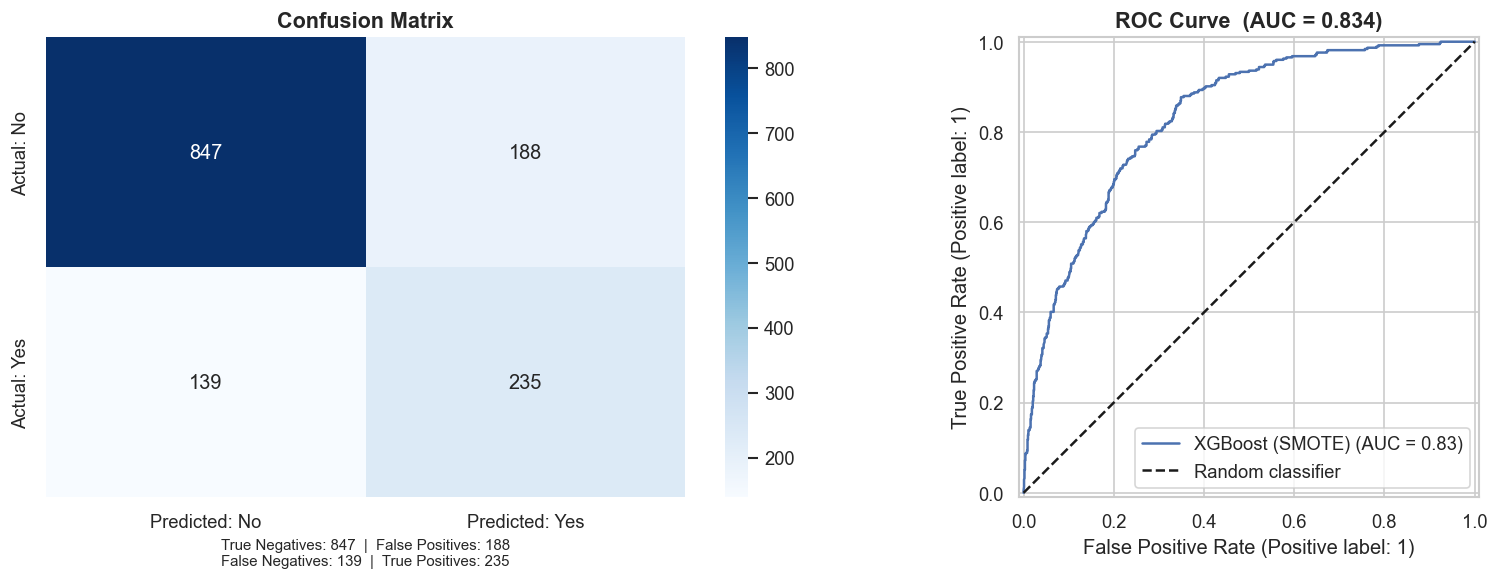

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# --- Confusion Matrix ---
cm = confusion_matrix(y_test, y_pred)
sns.heatmap(
    cm, annot=True, fmt='d', cmap='Blues', ax=axes[0],
    xticklabels=['Predicted: No', 'Predicted: Yes'],
    yticklabels=['Actual: No', 'Actual: Yes']
)
axes[0].set_title('Confusion Matrix', fontsize=13, fontweight='bold')

tn, fp, fn, tp = cm.ravel()
axes[0].set_xlabel(
    f'True Negatives: {tn}  |  False Positives: {fp}\nFalse Negatives: {fn}  |  True Positives: {tp}',
    fontsize=9
)

# --- ROC Curve ---
RocCurveDisplay.from_predictions(y_test, y_proba, ax=axes[1], name='XGBoost (SMOTE)')
axes[1].plot([0, 1], [0, 1], 'k--', label='Random classifier')
axes[1].set_title(f"ROC Curve  (AUC = {metrics['auc_roc']:.3f})", fontsize=13, fontweight='bold')
axes[1].legend()

plt.tight_layout()
plt.savefig('../images/model_evaluation.png', bbox_inches='tight')
plt.show()

## Step 5 — Compare with `scale_pos_weight`

An alternative to SMOTE is to keep the original training data and tell XGBoost to weight churners more heavily. Here we train that version and compare it with the SMOTE model on the same test set.

In [7]:
neg = (y_train == 0).sum()
pos = (y_train == 1).sum()
scale = round(neg / pos, 2)

model_weighted = XGBClassifier(
    scale_pos_weight=scale,
    random_state=42,
    eval_metric='logloss',
    n_estimators=200,
    max_depth=4,
    learning_rate=0.1
)
model_weighted.fit(X_train, y_train)

pred_w  = model_weighted.predict(X_test)
proba_w = model_weighted.predict_proba(X_test)[:, 1]

comparison = pd.DataFrame({
    'SMOTE': [
        accuracy_score(y_test, y_pred), roc_auc_score(y_test, y_proba),
        precision_score(y_test, y_pred), recall_score(y_test, y_pred), f1_score(y_test, y_pred)
    ],
    f'scale_pos_weight ({scale})': [
        accuracy_score(y_test, pred_w), roc_auc_score(y_test, proba_w),
        precision_score(y_test, pred_w), recall_score(y_test, pred_w), f1_score(y_test, pred_w)
    ]
}, index=['Accuracy', 'AUC-ROC', 'Precision (churn)', 'Recall (churn)', 'F1 (churn)']).round(4)

comparison

,SMOTE,scale_pos_weight (2.77)
Accuracy,0.7679,0.7509
AUC-ROC,0.8341,0.8381
Precision (churn),0.5556,0.5206
Recall (churn),0.6283,0.7754
F1 (churn),0.5897,0.6230


## Step 6 — Feature Importance

Which features does XGBoost rely on most? (This is global importance from the trees themselves; SHAP in the next step gives a more detailed view.)

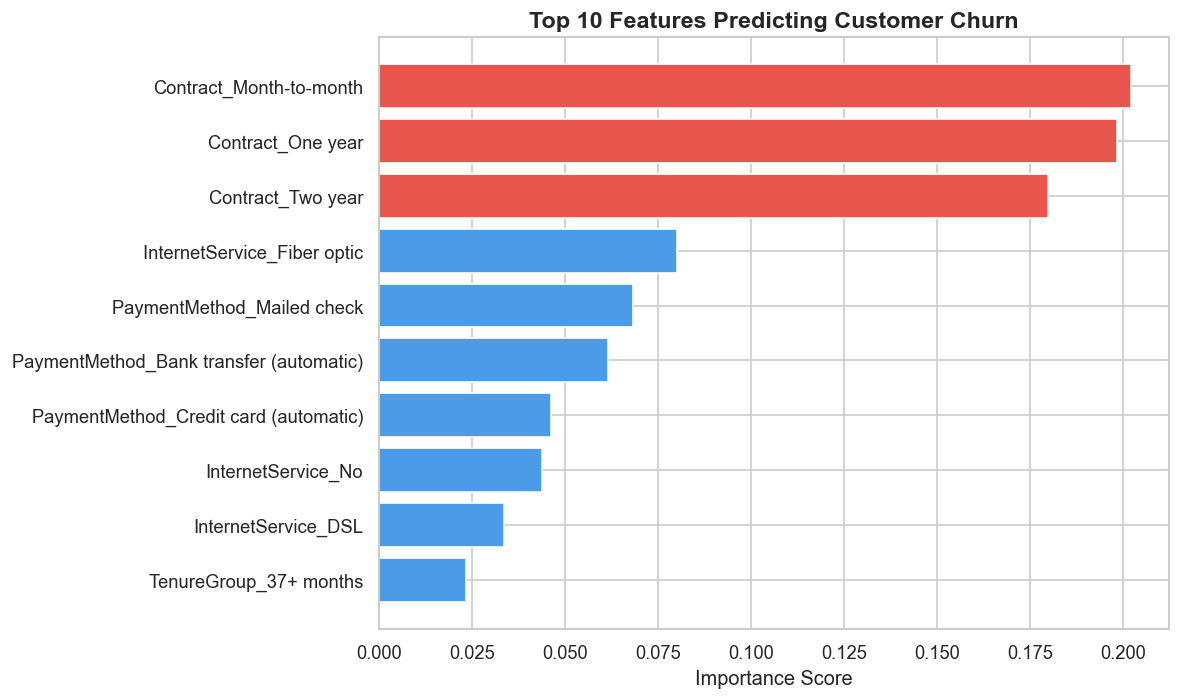


Top 10 features:
                                Feature  Importance
                Contract_Month-to-month    0.202110
                      Contract_One year    0.198196
                      Contract_Two year    0.179863
            InternetService_Fiber optic    0.080153
             PaymentMethod_Mailed check    0.068206
PaymentMethod_Bank transfer (automatic)    0.061547
  PaymentMethod_Credit card (automatic)    0.046156
                     InternetService_No    0.043877
                    InternetService_DSL    0.033481
                 TenureGroup_37+ months    0.023487


In [8]:
feature_importance = pd.DataFrame({
    'Feature': X.columns,
    'Importance': model.feature_importances_
}).sort_values('Importance', ascending=False)

top10 = feature_importance.head(10)

plt.figure(figsize=(10, 6))
colors = ['#E8554C' if i < 3 else '#4C9BE8' for i in range(len(top10))]
plt.barh(top10['Feature'][::-1], top10['Importance'][::-1], color=colors[::-1])
plt.xlabel('Importance Score', fontsize=12)
plt.title('Top 10 Features Predicting Customer Churn', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.savefig('../images/feature_importance.png', bbox_inches='tight')
plt.show()

print('\nTop 10 features:')
print(top10.to_string(index=False))

## Step 7 — Explainability with SHAP

**SHAP** explains *why* the model made each prediction. For every customer and every feature it computes how much that feature pushed the churn probability up or down.

- **Bar plot** — average size of each feature's impact (global importance)
- **Beeswarm plot** — each dot is one customer. Colour shows the feature value (red = high, blue = low) and position shows the push towards churn (right) or away from it (left)

In [9]:
%pip install "xgboost<3.1"


Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.1.2 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


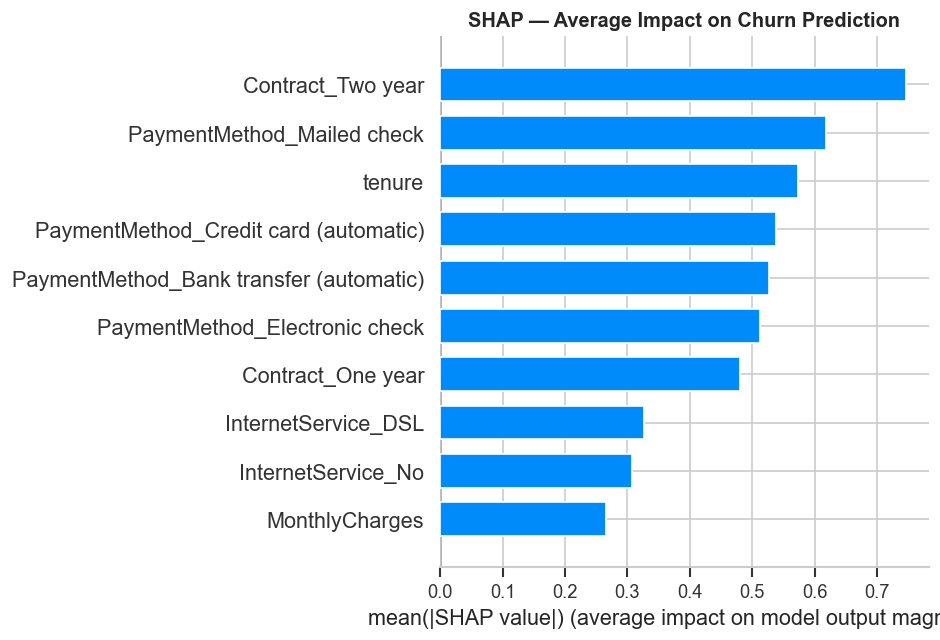

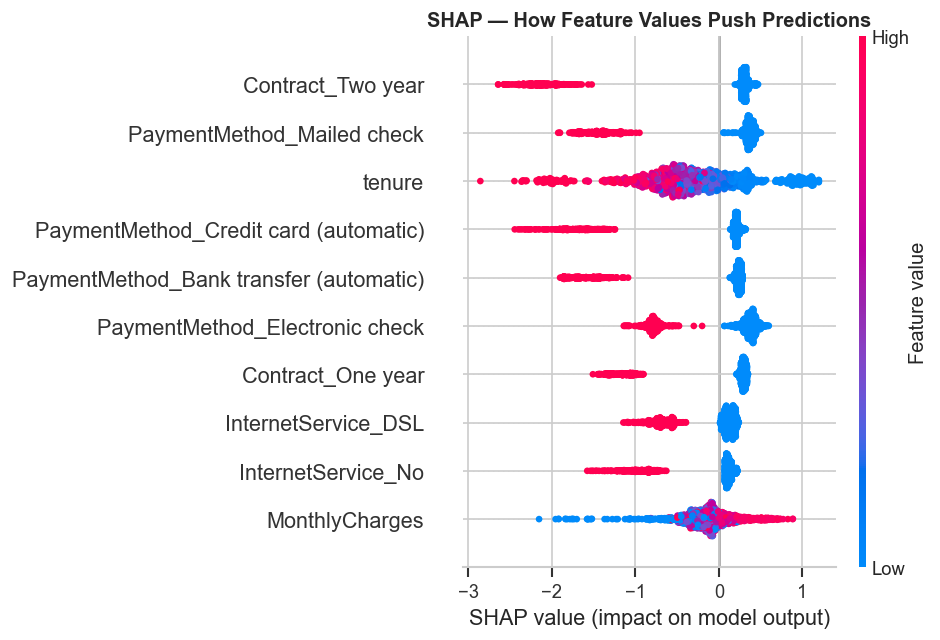

Top 10 churn drivers according to SHAP:
                                Feature  Mean |SHAP|
                      Contract_Two year     0.745698
             PaymentMethod_Mailed check     0.617841
                                 tenure     0.573294
  PaymentMethod_Credit card (automatic)     0.538482
PaymentMethod_Bank transfer (automatic)     0.526689
         PaymentMethod_Electronic check     0.513331
                      Contract_One year     0.480384
                    InternetService_DSL     0.326017
                     InternetService_No     0.307203
                         MonthlyCharges     0.266525


In [10]:
explainer   = shap.TreeExplainer(model)
shap_values = explainer(X_test)

# Global importance
plt.figure()
shap.summary_plot(shap_values, X_test, plot_type='bar', max_display=10, show=False)
plt.title('SHAP — Average Impact on Churn Prediction', fontweight='bold')
plt.tight_layout()
plt.savefig('../images/shap_bar.png', bbox_inches='tight')
plt.show()

# Direction of impact
plt.figure()
shap.summary_plot(shap_values, X_test, max_display=10, show=False)
plt.title('SHAP — How Feature Values Push Predictions', fontweight='bold')
plt.tight_layout()
plt.savefig('../images/shap_beeswarm.png', bbox_inches='tight')
plt.show()

mean_abs = pd.DataFrame({
    'Feature': X_test.columns,
    'Mean |SHAP|': np.abs(shap_values.values).mean(axis=0)
}).sort_values('Mean |SHAP|', ascending=False)
print('Top 10 churn drivers according to SHAP:')
print(mean_abs.head(10).to_string(index=False))

## Step 8 — Predict on a New Customer

Simulate a real-world prediction for a brand new customer not in the dataset, including the engineered features.

In [11]:
# High-risk customer: month-to-month, fiber optic, short tenure, no security add-ons
new_customer = pd.DataFrame([{
    'gender': 0, 'SeniorCitizen': 0, 'Partner': 1, 'Dependents': 0,
    'tenure': 12, 'PhoneService': 1, 'MultipleLines': 0,
    'OnlineSecurity': 0, 'OnlineBackup': 0, 'DeviceProtection': 0,
    'TechSupport': 0, 'StreamingTV': 0, 'StreamingMovies': 0,
    'PaperlessBilling': 1, 'MonthlyCharges': 89.5, 'TotalCharges': 1074.0,
    # engineered features
    'AvgMonthlySpend': 1074.0 / 12, 'NumAddOns': 0,
    'TenureGroup_0-12 months': 1, 'TenureGroup_13-36 months': 0, 'TenureGroup_37+ months': 0,
    # one-hot columns
    'InternetService_DSL': 0, 'InternetService_Fiber optic': 1, 'InternetService_No': 0,
    'Contract_Month-to-month': 1, 'Contract_One year': 0, 'Contract_Two year': 0,
    'PaymentMethod_Bank transfer (automatic)': 0,
    'PaymentMethod_Credit card (automatic)': 0,
    'PaymentMethod_Electronic check': 1,
    'PaymentMethod_Mailed check': 0
}])

# Make sure columns are in exactly the same order as the training data
new_customer = new_customer.reindex(columns=X.columns, fill_value=0)

prediction       = model.predict(new_customer)[0]
prediction_proba = model.predict_proba(new_customer)[0]

print('=' * 50)
print('  PREDICTION FOR NEW CUSTOMER')
print('=' * 50)
print('\n  Result :', 'WILL CHURN' if prediction == 1 else 'WILL NOT CHURN')
print(f'  Will not churn probability : {prediction_proba[0]:.2%}')
print(f'  Will churn probability     : {prediction_proba[1]:.2%}')
print('\n  Profile: Fiber optic, month-to-month, 12 months tenure, no security add-ons')

  PREDICTION FOR NEW CUSTOMER

  Result : WILL CHURN
  Will not churn probability : 12.39%
  Will churn probability     : 87.61%

  Profile: Fiber optic, month-to-month, 12 months tenure, no security add-ons


## Step 9 — Save the Model and Metrics

In [12]:
model.save_model('../models/churn_model.json')
print('Model saved to models/churn_model.json')

# Feature names, for deployment
pd.Series(X.columns.tolist()).to_csv('../models/feature_names.csv', index=False, header=False)
print('Feature names saved to models/feature_names.csv')

# Metrics, so the README numbers can be traced back to this run
metrics_out = {k: round(float(v), 4) for k, v in metrics.items()}
metrics_out.update({
    'train_rows_before_smote': int(len(X_train)),
    'train_rows_after_smote':  int(len(X_train_res)),
    'test_rows':               int(len(X_test)),
})
with open('../models/metrics.json', 'w') as f:
    json.dump(metrics_out, f, indent=2)
print('Metrics saved to models/metrics.json')
print(json.dumps(metrics_out, indent=2))

Model saved to models/churn_model.json
Feature names saved to models/feature_names.csv
Metrics saved to models/metrics.json
{
  "accuracy": 0.7679,
  "auc_roc": 0.8341,
  "precision_churn": 0.5556,
  "recall_churn": 0.6283,
  "f1_churn": 0.5897,
  "train_rows_before_smote": 5634,
  "train_rows_after_smote": 8278,
  "test_rows": 1409
}
